---
A Notebook that shows how the physics model/tools work, and makes a series of nice two dimensional plots

calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


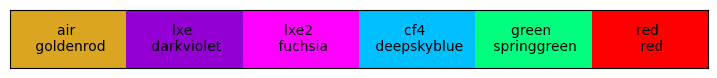

In [1]:
from lmfit import Model, Parameters
import lmfit

from scipy.stats import norm

import os
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.ndimage import gaussian_filter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Circle


from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 

# or do
# from DAAPS_TOOLKIT.PDEModel import *

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors()

rad2deg = 180/np.pi

---
## 2d Transmission plots

In [2]:
## global function we can hopefully control with the objects
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False):
    
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        nyield = (1240/wlen)/3.2
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        stepPerSigma = 3
        stepSize = smoothSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        fullerPDEVals = PDE_allArgs(newXVals, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma = None)
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=smoothSigma)
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)
    return PDE

def Simple_Transmission(wlen, theta1, tOxide): # theta 1 in deg
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.Wave_TotalTransmission(tOxide)
    return Ttotal

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


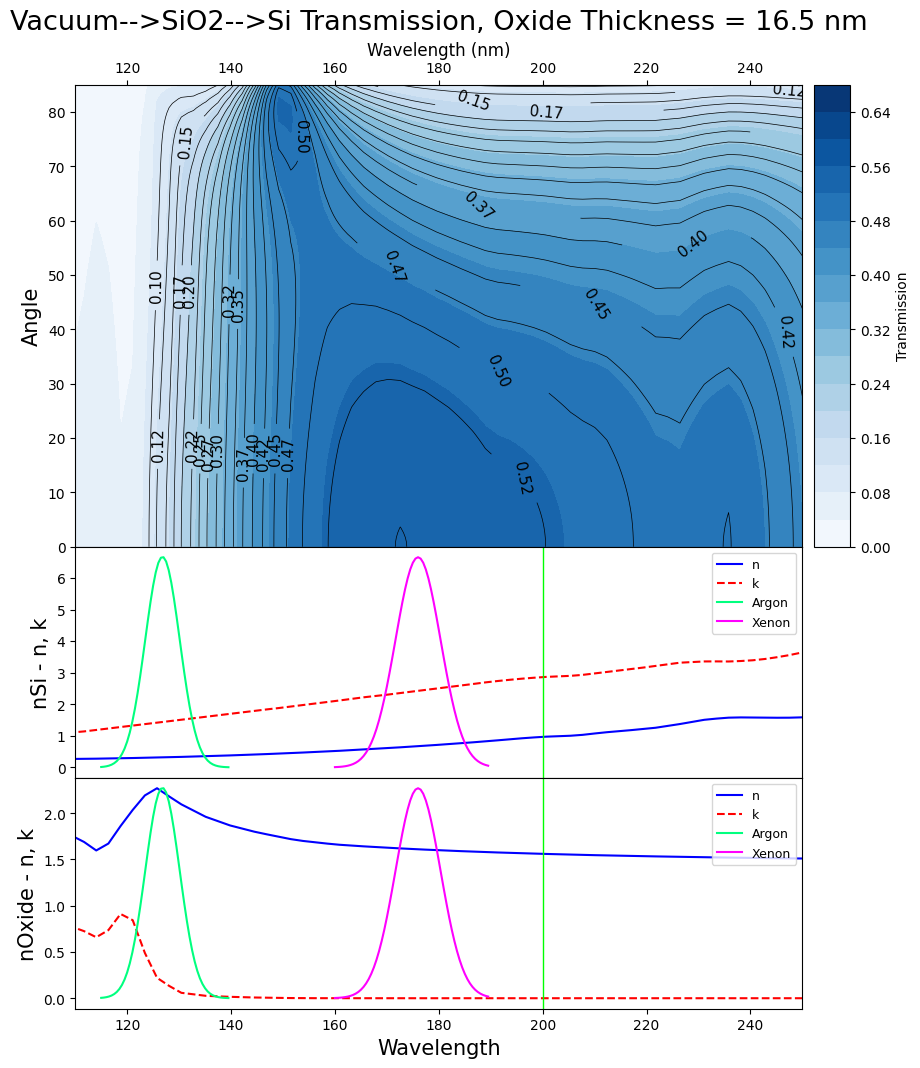

In [10]:
OpticsData.ResetInstance() ## important after the other stuff

plt.figure(figsize=(10, 12))
gs = gridspec.GridSpec(3, 2, width_ratios=[20, 1], height_ratios=[2, 1, 1])
fsize = 15

# Define the range of wavelength and angle
wavelength = np.linspace(100, 800, 300)
angle = np.linspace(0, 85, 100)

# Create a meshgrid of wavelength and angle
W, A = np.meshgrid(wavelength, angle)

# Calculate the transmission for each combination of wavelength and angle
transmission = Simple_Transmission(W, A, tOxide=16.5)

ax0 = plt.subplot(gs[0, 0])
mainContour = ax0.contourf(W, A, transmission, levels=20, cmap='Blues')
plt.colorbar(mainContour, cax=plt.subplot(gs[0, 1]), label='Transmission')

z_values = np.arange(0.1, 1., 0.025)
clines = ax0.contour(W, A, transmission, z_values, colors='black', linewidths=0.5)
ax0.clabel(clines, inline=True, fontsize=11, fmt='%1.2f')

ax0.xaxis.tick_top()
ax0.xaxis.set_label_position('top')
ax0.set_xlabel('Wavelength (nm)', fontsize=fsize*0.8)
ax0.set_ylabel('Angle', fontsize=fsize)
ax0.set_title('Vacuum-->SiO2-->Si Transmission, Oxide Thickness = 16.5 nm', pad = 40, fontsize=fsize*1.3)

xticks = ax0.get_xticks()
# xticks = np.append(xticks, [126.8, 176])
# for xt in xticks:
#     ax0.axvline(xt, color='lime', alpha = 0.7, linewidth=1.5)

# scintillation
xAr = np.arange(115, 140, 0.5)
yAr = norm.pdf(xAr, 126.8, 7.8/2.35)
xXe = np.arange(160, 190, 0.5)
yXe = norm.pdf(xXe, 176, 10.2/2.35)

callToMake = ["nSi", "nOxide"]
for i, call in enumerate(callToMake):
    nData = getattr(PhotonInfo(wavelength, dataHelper = OpticsData()), call)
    
    axnk = plt.subplot(gs[i+1, 0], sharex=ax0)
    axnk.plot(wavelength, np.real(nData), '-', color = "blue", label = "n")
    axnk.plot(wavelength, np.imag(nData), '--', color = "red", label = "k")
    
    axnk.plot(xAr, yAr/max(yAr) * max(np.real(nData)), color = ms.green.col, label = "Argon")
    axnk.plot(xXe, yXe/max(yXe) * max(np.real(nData)), color = ms.lxe2.col, label = "Xenon")
    
    for xt in xticks:
        axnk.axvline(xt, color='lime', linewidth=1)
    axnk.set_ylabel(f"{call} - n, k", fontsize=fsize)
    axnk.legend(fontsize=9, loc='upper right')

for i in range(1,gs.nrows):
    ax = plt.subplot(gs[i, 0])
    ax.label_outer()

axBottom = plt.subplot(gs[-1, 0])
axBottom.set_xlabel('Wavelength', fontsize=fsize)

# vlines = [190, 210, 225, 235]
# for xvline in vlines:
#     ax0.axvline(xvline, color='red', alpha = 0.7, linewidth=1.5)
    # axBottom.axvline(xvline, color='red', alpha = 0.7, linewidth=1.5)
# ax0.axvline(190, color='red', alpha = 0.7, linewidth=1.5)
# ax0.axvline(210, color='red', alpha = 0.7, linewidth=1.5)
# ax0.axvline(225, color='red', alpha = 0.7, linewidth=1.5)
# ax0.axvline(235, color='red', alpha = 0.7, linewidth=1.5)

ax0.set_xlim(110, 250)

# plt.tight_layout()
plt.subplots_adjust(hspace=0)
plt.subplots_adjust(wspace=0.03)
plt.show()

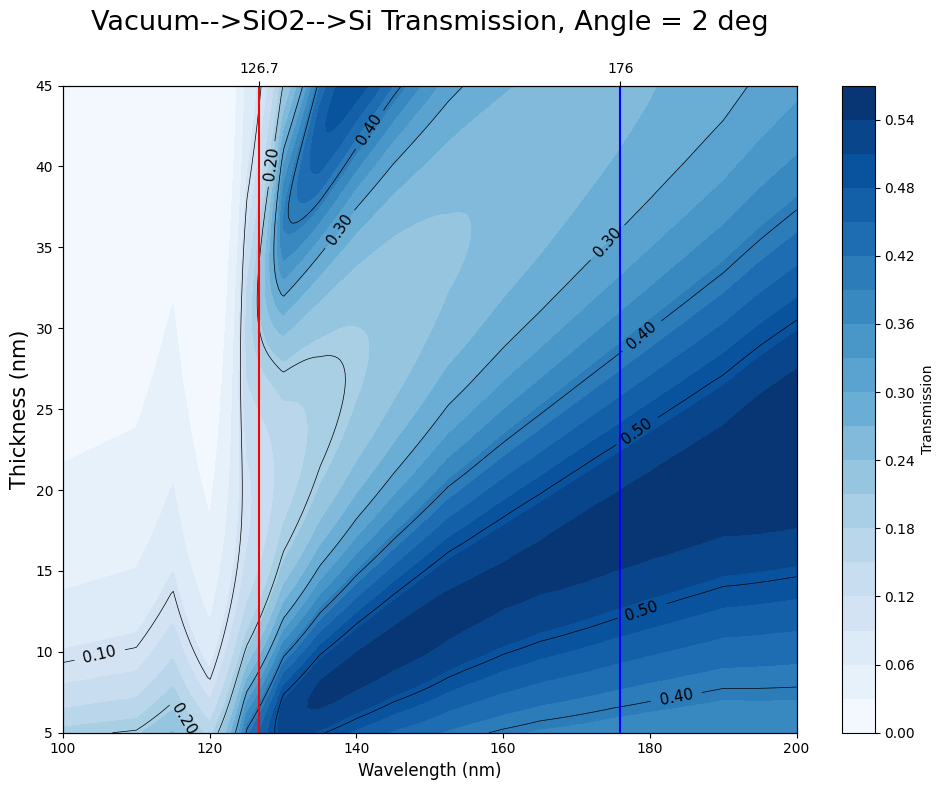

In [7]:
OpticsData.ResetInstance() ## important after calling other DH other stuff

fig, ax0 = plt.subplots(figsize=(10, 8))
fsize = 15

# Define the range of wavelength and angle
wavelength = np.linspace(100, 200, 300)
thickness = np.linspace(5, 45, 100)
fixedAngle = 2

# Create a meshgrid of wavelength and angle
W, T = np.meshgrid(wavelength, thickness)

# Calculate the transmission for each combination of wavelength and angle
transmission = Simple_Transmission(W, theta1 = fixedAngle, tOxide=T)

mainContour = ax0.contourf(W, T, transmission, levels=20, cmap='Blues')
plt.colorbar(mainContour, label='Transmission')

z_values = np.arange(0.1, 1., 0.1)
clines = ax0.contour(W, T, transmission, z_values, colors='black', linewidths=0.5)
ax0.clabel(clines, inline=True, fontsize=11, fmt='%1.2f')

## other ticks
# Plot vertical lines at x=126 and x=175
scintWls = [126.7, 176]
ax0.axvline(x=scintWls[0], color='red')
ax0.axvline(x=scintWls[1], color='blue')

# ax0.set_xlim(110, 400)

# Create a second x-axis
ax2 = ax0.twiny()

# # Move the second x-axis to the bottom
# ax2.xaxis.set_ticks_position('bottom')
# ax2.xaxis.set_label_position('bottom')
# ax2.spines['bottom'].set_position(('outward', 40))

# Set the limits of the second x-axis to match the first x-axis
ax2.set_xlim(ax0.get_xlim())

# Set the tick locations and labels on the second x-axis
ax2.set_xticks(scintWls)
ax2.set_xticklabels([f"{scintWls[0]}", f"{scintWls[1]}"])
##############

ax0.set_xlabel('Wavelength (nm)', fontsize=fsize*0.8)
ax0.set_ylabel('Thickness (nm)', fontsize=fsize)
ax0.set_title(f'Vacuum-->SiO2-->Si Transmission, Angle = {fixedAngle} deg', pad = 40, fontsize=fsize*1.3)

plt.tight_layout()
plt.show()